# Puntos 13 y 14 – Ciclo anual de la precipitación y comparación de productos
**Trabajo 1 de Hidroclimatología · Cuenca del río Cauca hasta Hidroituango**

- **Punto 13:** ciclo anual climatológico de la cuenca,

  $$\overline{P}_m = \frac{1}{N}\sum_{j=1}^{N} P_{m,j}, \qquad m = 1,\dots,12$$

  con los 12 mapas mensuales; meses secos y húmedos; régimen unimodal o bimodal; variación espacial del ciclo.
- **Punto 14:** comparación del ciclo del IDEAM con CHIRPS, ERA5-Land y ERA5:
  - magnitud, estacionalidad, meses de máximos y mínimos, amplitud;
  - sesgo, RMSE y correlación con n = 12;
  - diagrama de Taylor;
  - conclusión sobre qué producto representa mejor la P media, el balance, el ciclo anual y la distribución espacial.

**Archivos necesarios:**
- `P_IDEAM_mensual.tif`, `P_IDEAM_anual.tif` y `estaciones_P_seleccionadas.csv` (punto 3)
- `P_CHIRPS_mensual.tif`, `P_ERA5L_mensual.tif`, `P_ERA5_mensual.tif` y sus `_anual.tif` (punto 11)
- `resumen_balance_productos.csv` (punto 12, opcional)
- `cuenca_cauca.gpkg`

## 0. Instalación de librerías
Solo si no las instaló antes. Después de instalar, reinicie el kernel.

In [1]:
%pip install numpy pandas matplotlib geopandas rasterio pyproj shapely

Note: you may need to restart the kernel to use updated packages.


## 1. Librerías, parámetros y funciones de apoyo

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from scipy.signal import find_peaks
from matplotlib.colors import ListedColormap

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

# ----------------------------- PARÁMETROS -----------------------------
CRS = "EPSG:3116"
CUENCA = "cuenca_cauca.gpkg"
RIO = "rio_principal.gpkg"
ESTACIONES_P = "estaciones_P_seleccionadas.csv"
RESUMEN_BALANCE = "resumen_balance_productos.csv"
PROMINENCIA = 0.10        # un pico cuenta como "temporada lluviosa" si sobresale ≥ 10 % de la P media mensual
# ----------------------------------------------------------------------

MESES = ["ENE", "FEB", "MAR", "ABR", "MAY", "JUN", "JUL", "AGO", "SEP", "OCT", "NOV", "DIC"]
PRODUCTOS = ["IDEAM", "CHIRPS", "ERA5L", "ERA5"]
NOMBRE = {"CHIRPS": "CHIRPS", "ERA5L": "ERA5-Land", "ERA5": "ERA5", "IDEAM": "IDEAM"}
COLOR = {"IDEAM": "#252525", "CHIRPS": "#1b9e77", "ERA5L": "#d95f02", "ERA5": "#7570b3"}


def valor_en_punto(arr, info, x, y):
    T = info["transform"]
    col = int(np.floor((x - T.c) / T.a)); fila = int(np.floor((y - T.f) / T.e))
    h, w = info["shape"]
    if 0 <= fila < h and 0 <= col < w and not np.ma.getmaskarray(arr)[fila, col]:
        return float(arr[fila, col])
    return np.nan


def picos(ciclo):
    # Meses (índices 0-11) que son máximos del ciclo anual, considerando que diciembre empalma con enero
    x = np.asarray(ciclo, float)
    p, _ = find_peaks(np.r_[x, x, x], prominence=PROMINENCIA * x.mean())
    return sorted({int(i - 12) for i in p if 12 <= i < 24})

In [3]:
# ----------------------- Funciones de apoyo SIG -----------------------
import rasterio
from rasterio import features
from rasterio.warp import reproject, Resampling
from rasterio.transform import from_origin
from pyproj import Transformer
from shapely.geometry import shape
from shapely.ops import unary_union


def leer_raster(ruta):
    # Devuelve (arreglo enmascarado, info). Si el archivo tiene varias bandas: arreglo (bandas, filas, columnas)
    with rasterio.open(ruta) as src:
        arr = src.read(masked=True).astype("float64")
        info = {"transform": src.transform, "crs": src.crs, "shape": (src.height, src.width),
                "profile": src.profile.copy()}
    return (arr[0] if arr.shape[0] == 1 else arr), info


def guardar_raster(ruta, arr, info, nodata=-9999.0, descripciones=None, dtype="float32"):
    a = np.ma.masked_invalid(np.ma.asarray(arr, dtype="float64"))
    if a.ndim == 2:
        a = a[None]
    perfil = info["profile"].copy()
    perfil.update(driver="GTiff", dtype=dtype, nodata=nodata, count=a.shape[0], compress="lzw")
    with rasterio.open(ruta, "w", **perfil) as dst:
        dst.write(a.filled(nodata).astype(dtype))
        for i, d in enumerate(descripciones or [], start=1):
            dst.set_band_description(i, d)


def coords_celdas(info):
    # Coordenadas (x, y) del centro de cada celda, en el SRC del ráster
    T = info["transform"]
    filas, cols = np.indices(info["shape"])
    return T.a * (cols + 0.5) + T.b * (filas + 0.5) + T.c, T.d * (cols + 0.5) + T.e * (filas + 0.5) + T.f


def a_lonlat(x, y, crs):
    lon, lat = Transformer.from_crs(crs, "EPSG:4326", always_xy=True).transform(np.asarray(x), np.asarray(y))
    return np.asarray(lon), np.asarray(lat)


def de_lonlat(lon, lat, crs):
    x, y = Transformer.from_crs("EPSG:4326", crs, always_xy=True).transform(np.asarray(lon), np.asarray(lat))
    return np.asarray(x), np.asarray(y)


def remuestrear_a_grilla(arr, lon, lat, info, metodo="bilinear"):
    # Lleva un campo en grilla regular lon/lat (2D o 3D con el tiempo primero) a la grilla del DEM
    arr = np.asarray(arr, dtype="float64")
    if lat[0] < lat[-1]:                       # filas de norte a sur
        arr, lat = arr[..., ::-1, :], lat[::-1]
    dx, dy = abs(lon[1] - lon[0]), abs(lat[1] - lat[0])
    src_T = from_origin(lon.min() - dx / 2, lat.max() + dy / 2, dx, dy)
    capas = arr if arr.ndim == 3 else arr[None]
    salida = np.full((capas.shape[0],) + info["shape"], np.nan)
    for k in range(capas.shape[0]):
        reproject(source=np.ascontiguousarray(capas[k]), destination=salida[k], src_transform=src_T,
                  src_crs="EPSG:4326", src_nodata=np.nan, dst_transform=info["transform"], dst_crs=info["crs"],
                  dst_nodata=np.nan, resampling=getattr(Resampling, metodo))
    return salida if arr.ndim == 3 else salida[0]


def mascara_geometria(geom, info):
    # True en las celdas cuyo centro cae dentro de la geometría
    return features.geometry_mask([geom], out_shape=info["shape"], transform=info["transform"], invert=True)


def poligonizar(mascara, info):
    geoms = [shape(g) for g, v in features.shapes(mascara.astype("uint8"), mask=mascara,
                                                    transform=info["transform"]) if v == 1]
    return unary_union(geoms)

In [4]:
def decorar(ax, titulo, ext, cuenca, rio=None):
    # Límite de la cuenca, río, flecha de norte, barra de escala y SRC
    cuenca.boundary.plot(ax=ax, color="k", lw=0.8)
    if rio is not None:
        rio.plot(ax=ax, color="#08306b", lw=1.0)
    ax.annotate("", xy=(0.93, 0.93), xytext=(0.93, 0.84), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", color="k", lw=1.5))
    ax.text(0.93, 0.945, "N", transform=ax.transAxes, ha="center", fontsize=12, fontweight="bold")
    x0 = ext[0] + 0.06 * (ext[1] - ext[0]); y0 = ext[2] + 0.04 * (ext[3] - ext[2])
    ax.plot([x0, x0 + 50000], [y0, y0], "k-", lw=3)
    ax.text(x0 + 25000, y0 + 0.012 * (ext[3] - ext[2]), "50 km", ha="center", fontsize=8)
    ax.set_title(titulo, fontsize=11)
    ax.text(0.02, 0.005, "MAGNA-SIRGAS / Colombia Bogotá zone (EPSG:3116)", transform=ax.transAxes, fontsize=7,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1))
    ax.ticklabel_format(style="plain"); ax.tick_params(labelsize=7)
    ax.locator_params(axis="x", nbins=4)
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3]); ax.set_aspect("equal")


def extension(info):
    T = info["transform"]; h, w = info["shape"]
    return [T.c, T.c + T.a * w, T.f + T.e * h, T.f]


def mapa(arr, info, titulo, etiqueta, cuenca, rio=None, cmap="viridis", archivo=None, vmin=None, vmax=None, ax=None):
    ext = extension(info)
    propio = ax is None
    if propio:
        fig, ax = plt.subplots(figsize=(6, 9))
    im = ax.imshow(arr, extent=ext, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    if propio:
        plt.colorbar(im, ax=ax, shrink=0.6, label=etiqueta)
    decorar(ax, titulo, ext, cuenca, rio)
    if propio:
        fig.tight_layout()
        if archivo:
            fig.savefig(archivo, dpi=200)
        plt.show()
    return im

cuenca = gpd.read_file(CUENCA).to_crs(CRS)
rio = gpd.read_file(RIO).to_crs(CRS) if os.path.exists(RIO) else None

## 2. Lectura de los mapas mensuales y ciclo anual de la cuenca

In [5]:
mens, anual = {}, {}
for prod in PRODUCTOS:
    if not os.path.exists(f"P_{prod}_mensual.tif"):
        print(f"{prod}: falta P_{prod}_mensual.tif; se omite"); continue
    mens[prod], info = leer_raster(f"P_{prod}_mensual.tif")
    anual[prod] = mens[prod].sum(axis=0)
PRODUCTOS = list(mens)
mascara = np.ma.getmaskarray(anual["IDEAM"])
for prod in PRODUCTOS:
    mascara = mascara | np.ma.getmaskarray(anual[prod])
for prod in PRODUCTOS:
    mens[prod] = np.ma.masked_array(mens[prod], mask=np.broadcast_to(mascara, mens[prod].shape))
    anual[prod] = np.ma.masked_array(anual[prod], mask=mascara)

ciclos = pd.DataFrame({NOMBRE[p]: [mens[p][m].mean() for m in range(12)] for p in PRODUCTOS}, index=MESES)
ciclos.loc["ANUAL"] = ciclos.sum()
ciclos.to_csv("ciclo_anual_cuenca_productos.csv", encoding="utf-8-sig")
display(ciclos.round(1).T)
ciclos = ciclos.drop("ANUAL")

,ENE,FEB,MAR,ABR,MAY,JUN,JUL,AGO,SEP,OCT,NOV,DIC,ANUAL
IDEAM,121.9,120.7,169.8,218.1,212.0,140.8,114.6,112.9,166.5,239.3,227.7,156.7,2001.0
CHIRPS,116.7,118.7,166.6,223.5,219.0,141.1,112.5,115.2,164.0,245.3,232.5,161.9,2017.0
ERA5-Land,364.3,385.7,492.3,594.6,597.0,521.4,496.6,498.6,538.3,561.7,515.4,424.9,5990.9
ERA5,364.9,385.4,489.0,588.7,592.1,528.1,512.9,513.0,539.7,557.6,511.8,424.0,6007.2


## 3. Punto 13 – Ciclo anual de la precipitación (IDEAM)
### 3.1 Gráfica del ciclo, meses secos y húmedos, régimen
- **Mes húmedo:** su lluvia supera el promedio mensual ($P_{anual}/12$).
- **Mes seco:** queda por debajo de ese promedio.
- **Régimen:** se cuentan los máximos del ciclo que sobresalen al menos un 10 % de la media mensual. Uno es
  **unimodal** y dos es **bimodal**.

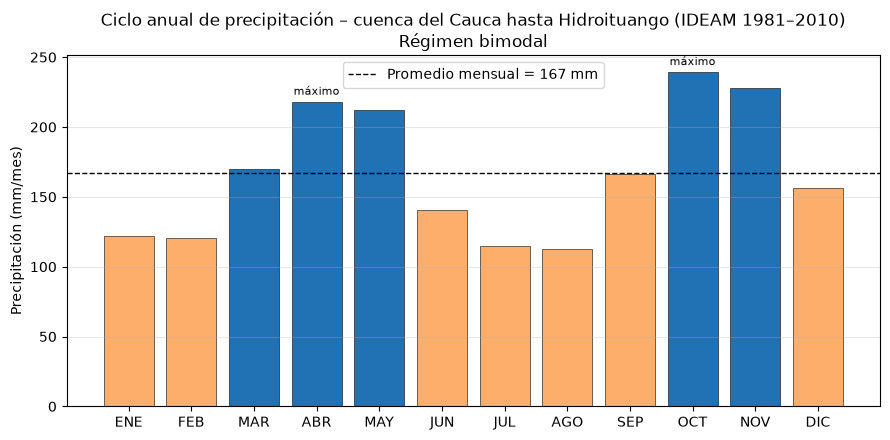

P anual de la cuenca: 2,001 mm | régimen bimodal; máximos en: ['ABR', 'OCT']
Meses húmedos: ['MAR', 'ABR', 'MAY', 'OCT', 'NOV']
Meses secos:   ['ENE', 'FEB', 'JUN', 'JUL', 'AGO', 'SEP', 'DIC']
Mes más lluvioso: OCT (239 mm) | mes más seco: AGO (113 mm)


In [6]:
ci = ciclos["IDEAM"]
media_m = ci.mean()
estado = np.where(ci > media_m, "húmedo", "seco")
pk = picos(ci)
regimen = {1: "unimodal", 2: "bimodal"}.get(len(pk), f"{len(pk)} picos")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(MESES, ci, color=["#2171b5" if e == "húmedo" else "#fdae6b" for e in estado], edgecolor="k", lw=0.4)
ax.axhline(media_m, color="k", ls="--", lw=1, label=f"Promedio mensual = {media_m:.0f} mm")
for i in pk:
    ax.annotate("máximo", (i, ci.iloc[i]), xytext=(0, 5), textcoords="offset points", ha="center", fontsize=8)
ax.set(ylabel="Precipitación (mm/mes)",
       title=f"Ciclo anual de precipitación – cuenca del Cauca hasta Hidroituango (IDEAM 1981–2010)\nRégimen {regimen}")
ax.legend(); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig("fig_ciclo_anual_IDEAM.png", dpi=200)
plt.show()

print(f"P anual de la cuenca: {ci.sum():,.0f} mm | régimen {regimen}; máximos en: {[MESES[i] for i in pk]}")
print("Meses húmedos:", [m for m, e in zip(MESES, estado) if e == "húmedo"])
print("Meses secos:  ", [m for m, e in zip(MESES, estado) if e == "seco"])
print(f"Mes más lluvioso: {ci.idxmax()} ({ci.max():.0f} mm) | mes más seco: {ci.idxmin()} ({ci.min():.0f} mm)")

### 3.2 Los 12 mapas mensuales

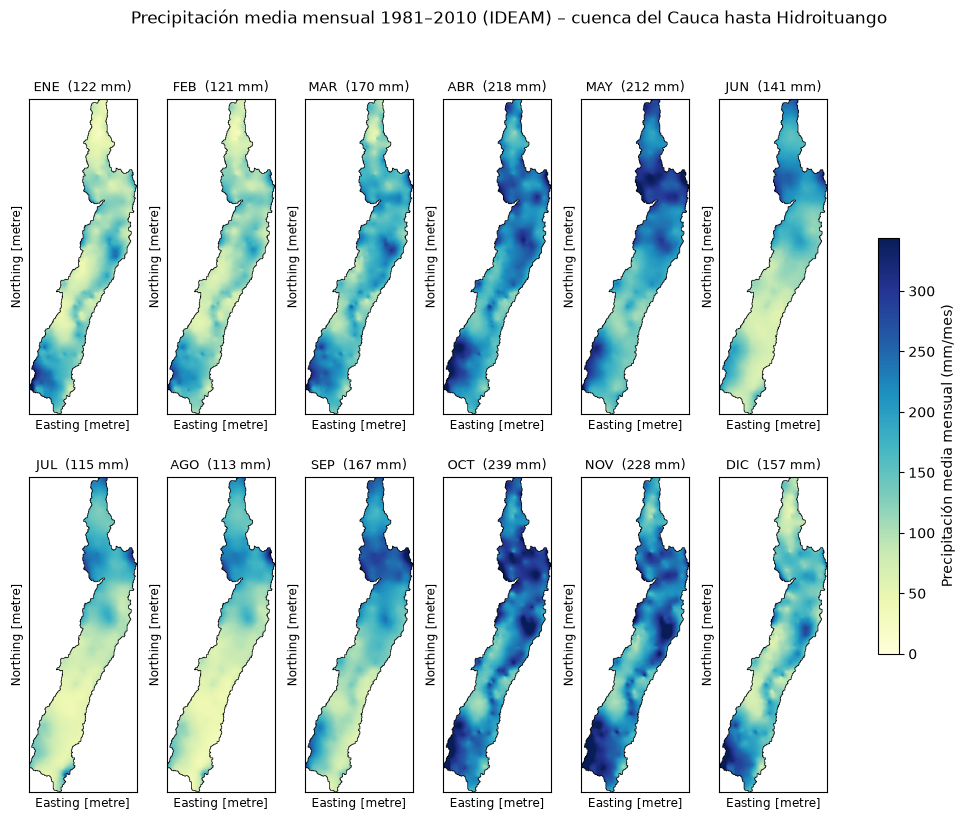

In [7]:
ext = extension(info)
vmax = np.percentile(mens["IDEAM"].compressed(), 99)
fig, axs = plt.subplots(2, 6, figsize=(13, 9))
for m, ax in enumerate(axs.ravel()):
    im = ax.imshow(mens["IDEAM"][m], extent=ext, cmap="YlGnBu", vmin=0, vmax=vmax, interpolation="nearest")
    cuenca.boundary.plot(ax=ax, color="k", lw=0.5)
    ax.set_title(f"{MESES[m]}  ({ci.iloc[m]:.0f} mm)", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3]); ax.set_aspect("equal")
fig.colorbar(im, ax=axs, shrink=0.6, label="Precipitación media mensual (mm/mes)")
fig.suptitle("Precipitación media mensual 1981–2010 (IDEAM) – cuenca del Cauca hasta Hidroituango")
fig.savefig("fig_P_mensual_12mapas_IDEAM.png", dpi=200, bbox_inches="tight")
plt.show()

### 3.3 Variación espacial del ciclo anual
Se construyen tres mapas a partir de los 12 mapas mensuales:
- **Mes de máxima precipitación** de cada celda.
- **Número de temporadas lluviosas** de cada celda: 1 = unimodal, 2 = bimodal.
- **Índice de estacionalidad** de Walsh y Lawler (1981), $SI = \frac{1}{P_{anual}}\sum_{m}\left|P_m - \frac{P_{anual}}{12}\right|$.
  Un valor menor de 0,2 indica lluvia muy repartida en el año; uno mayor de 0,4 indica una estación seca marcada.

Además, se comparan los ciclos de las franjas sur, centro y norte de la cuenca.

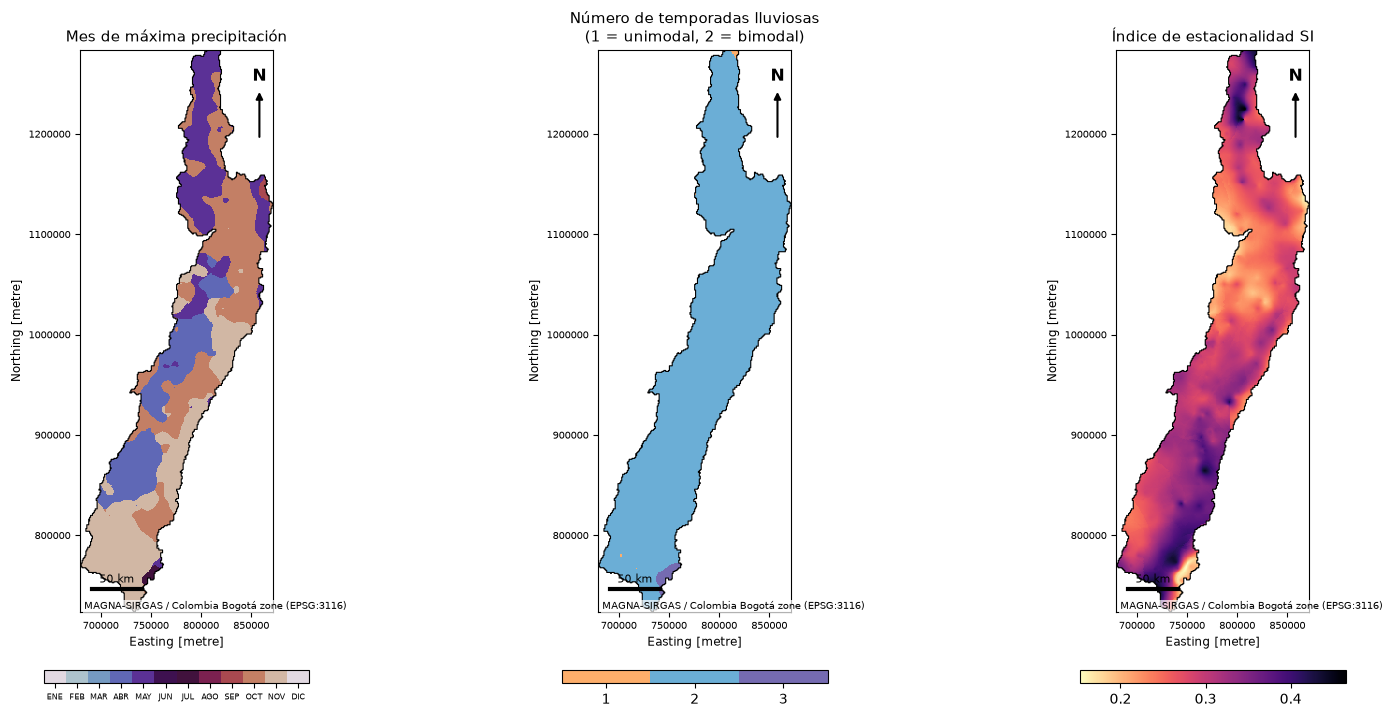

Fracción del área por número de temporadas lluviosas: {1: '0.1 %', 2: '99.0 %', 3: '0.8 %'}


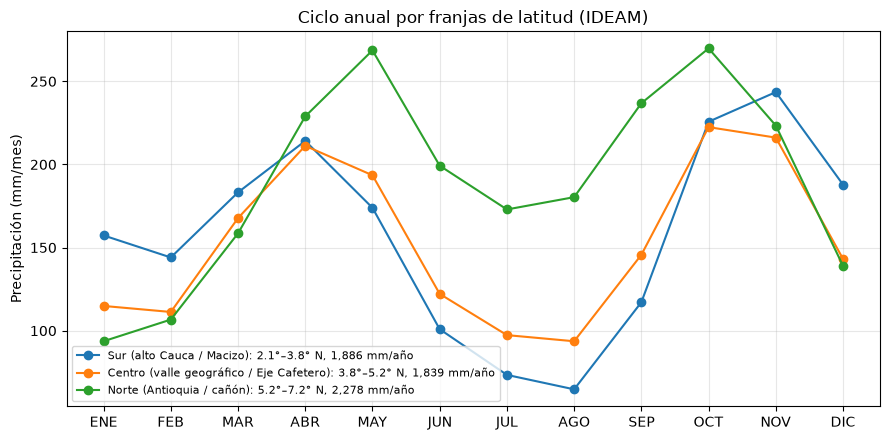

In [8]:
M = mens["IDEAM"]
celdas = np.nonzero(~mascara)
datos_c = M.data[:, celdas[0], celdas[1]].T                     # (celdas, 12)
mes_max = np.ma.masked_array(np.full(mascara.shape, -1), mask=mascara)
mes_max[celdas] = datos_c.argmax(axis=1)
n_picos = np.ma.masked_array(np.zeros(mascara.shape), mask=mascara)
n_picos[celdas] = [len(picos(c)) for c in datos_c]
SI = np.ma.masked_array(np.zeros(mascara.shape), mask=mascara)
tot = datos_c.sum(axis=1)
SI[celdas] = np.abs(datos_c - tot[:, None] / 12).sum(axis=1) / tot

fig, axs = plt.subplots(1, 3, figsize=(16, 8))
im0 = mapa(mes_max, info, "Mes de máxima precipitación", "", cuenca, rio, cmap=ListedColormap(plt.cm.twilight(np.linspace(0, 1, 12))),
           vmin=-0.5, vmax=11.5, ax=axs[0])
cb = plt.colorbar(im0, ax=axs[0], shrink=0.5, orientation="horizontal", pad=0.08, ticks=range(12))
cb.ax.set_xticklabels(MESES, fontsize=6)
im1 = mapa(n_picos, info, "Número de temporadas lluviosas\n(1 = unimodal, 2 = bimodal)", "", cuenca, rio,
           cmap=ListedColormap(["#fdae6b", "#6baed6", "#756bb1"]), vmin=0.5, vmax=3.5, ax=axs[1])
plt.colorbar(im1, ax=axs[1], shrink=0.5, orientation="horizontal", pad=0.08, ticks=[1, 2, 3])
im2 = mapa(SI, info, "Índice de estacionalidad SI", "", cuenca, rio, cmap="magma_r", ax=axs[2])
plt.colorbar(im2, ax=axs[2], shrink=0.5, orientation="horizontal", pad=0.08)
fig.tight_layout(); fig.savefig("fig_variacion_espacial_ciclo.png", dpi=200)
plt.show()
print("Fracción del área por número de temporadas lluviosas:",
      {int(k): f"{100 * v:.1f} %" for k, v in pd.Series(n_picos.compressed()).value_counts(normalize=True).sort_index().items()})

xc, yc = coords_celdas(info)
_, lat = a_lonlat(xc[celdas], yc[celdas], info["crs"])
cortes = np.quantile(lat, [1 / 3, 2 / 3])
zona = np.digitize(lat, cortes)
fig, ax = plt.subplots(figsize=(9, 4.5))
for z, nom in enumerate(["Sur (alto Cauca / Macizo)", "Centro (valle geográfico / Eje Cafetero)", "Norte (Antioquia / cañón)"]):
    sel = zona == z
    ax.plot(MESES, datos_c[sel].mean(axis=0), marker="o",
            label=f"{nom}: {lat[sel].min():.1f}°–{lat[sel].max():.1f}° N, {datos_c[sel].sum(axis=1).mean():,.0f} mm/año")
ax.set(ylabel="Precipitación (mm/mes)", title="Ciclo anual por franjas de latitud (IDEAM)")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("fig_ciclo_por_franjas.png", dpi=200)
plt.show()

**Para el informe (punto 13):**
- En la mayor parte de la cuenca el régimen es **bimodal**. Se debe al doble paso de la Zona de Convergencia
  Intertropical (ZCIT) sobre los Andes colombianos: hay lluvias de marzo a mayo y de septiembre a noviembre, y
  periodos más secos en diciembre–febrero y junio–agosto.
- Octubre–noviembre suele ser la temporada más lluviosa.
- Hacia el norte, en Antioquia y cerca de Hidroituango, el periodo seco de mitad de año se debilita y el régimen
  tiende a **unimodal**, con lluvias de abril a noviembre.
- Use los tres mapas y las franjas para describir dónde cambia el régimen.

## 4. Punto 14 – Comparación del ciclo anual entre productos
### 4.1 Ciclos y métricas (n = 12)
$$Bias = \frac{1}{n}\sum (P_i^{prod} - P_i^{IDEAM}),\quad RMSE = \sqrt{\frac{1}{n}\sum (P_i^{prod} - P_i^{IDEAM})^2},\quad
r = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum (x_i-\bar x)^2\sum (y_i-\bar y)^2}}$$

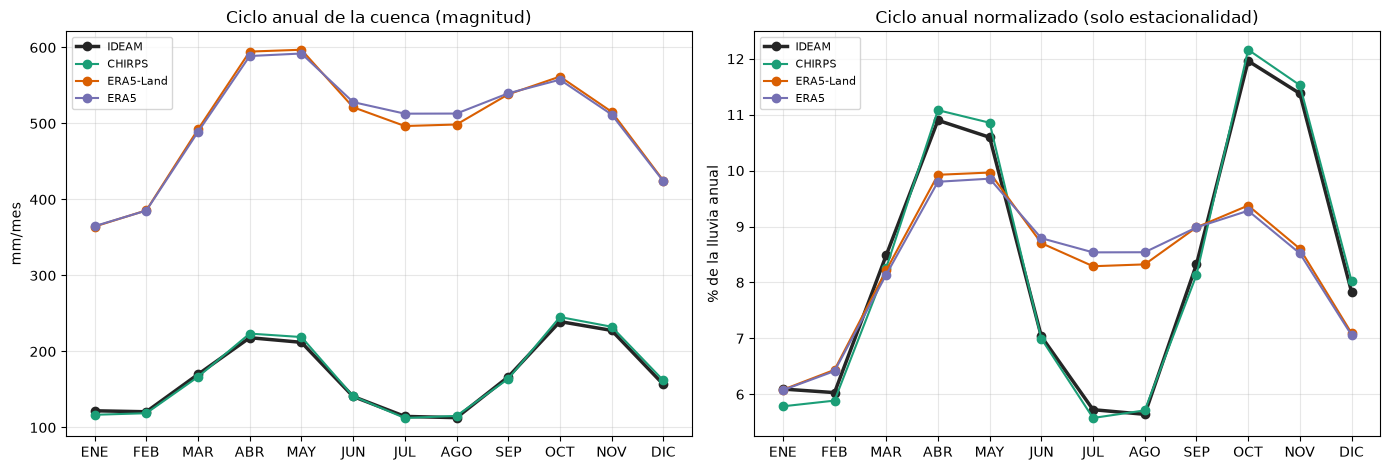

,P anual (mm),Bias (mm/mes),Bias (%),RMSE (mm/mes),r,régimen,meses de máximo,mes mínimo,"amplitud (máx − mín, mm)",desv. estándar (mm)
producto,,,,,,,,,,
IDEAM,2001.03,NaN,NaN,NaN,NaN,bimodal,"ABR, OCT",AGO,126.44,44.92
CHIRPS,2017.04,1.33,0.80,4.30,1.00,bimodal,"ABR, OCT",JUL,132.82,47.89
ERA5-Land,5990.86,332.49,199.39,336.58,0.68,bimodal,"MAY, OCT",ENE,232.68,71.60
ERA5,6007.22,333.85,200.21,338.42,0.62,unimodal,MAY,ENE,227.18,70.59


In [9]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
for prod in PRODUCTOS:
    c = ciclos[NOMBRE[prod]]
    kw = dict(color=COLOR[prod], marker="o", lw=2.5 if prod == "IDEAM" else 1.5, label=NOMBRE[prod])
    axs[0].plot(MESES, c, **kw)
    axs[1].plot(MESES, 100 * c / c.sum(), **kw)
axs[0].set(ylabel="mm/mes", title="Ciclo anual de la cuenca (magnitud)")
axs[1].set(ylabel="% de la lluvia anual", title="Ciclo anual normalizado (solo estacionalidad)")
for a in axs: a.grid(alpha=0.3); a.legend(fontsize=8)
fig.tight_layout(); fig.savefig("fig_ciclos_productos.png", dpi=200)
plt.show()

obs = ciclos["IDEAM"].to_numpy()
filas = []
for prod in PRODUCTOS:
    s = ciclos[NOMBRE[prod]].to_numpy()
    e = s - obs
    pk_ = picos(s)
    filas.append({"producto": NOMBRE[prod], "P anual (mm)": s.sum(),
                  "Bias (mm/mes)": e.mean() if prod != "IDEAM" else np.nan,
                  "Bias (%)": 100 * e.mean() / obs.mean() if prod != "IDEAM" else np.nan,
                  "RMSE (mm/mes)": np.sqrt((e ** 2).mean()) if prod != "IDEAM" else np.nan,
                  "r": np.corrcoef(obs, s)[0, 1] if prod != "IDEAM" else np.nan,
                  "régimen": {1: "unimodal", 2: "bimodal"}.get(len(pk_), f"{len(pk_)} picos"),
                  "meses de máximo": ", ".join(MESES[i] for i in pk_),
                  "mes mínimo": MESES[int(s.argmin())],
                  "amplitud (máx − mín, mm)": s.max() - s.min(), "desv. estándar (mm)": s.std()})
met = pd.DataFrame(filas).set_index("producto")
met.to_csv("metricas_ciclo_anual.csv", encoding="utf-8-sig")
display(met.round(2))

### 4.2 Diagrama de Taylor (hidropunto)
El **diagrama de Taylor** (Taylor, 2001) resume en una sola figura qué tan parecido es cada producto a una
referencia, aquí el ciclo del IDEAM. Usa tres estadísticos relacionados geométricamente por la ley de cosenos:

$$E'^2 = \sigma_p^2 + \sigma_o^2 - 2\,\sigma_p\,\sigma_o\,r$$

- **Distancia al origen:** desviación estándar del producto, $\sigma_p$. Indica si reproduce la **amplitud** de la
  variación.
- **Ángulo:** coeficiente de correlación $r$ (ángulo = arccos r). Indica si reproduce la **forma y la fase** del ciclo.
- **Distancia a la estrella de referencia:** error cuadrático medio centrado $E'$, es decir, el RMSE sin el sesgo.

El mejor producto es el que queda **más cerca de la estrella**. Como el diagrama no muestra el sesgo, se
complementa con la tabla de la sección 4.1. Se usa mucho para escoger, entre varios modelos o productos, los que
mejor representan el clima de una región.

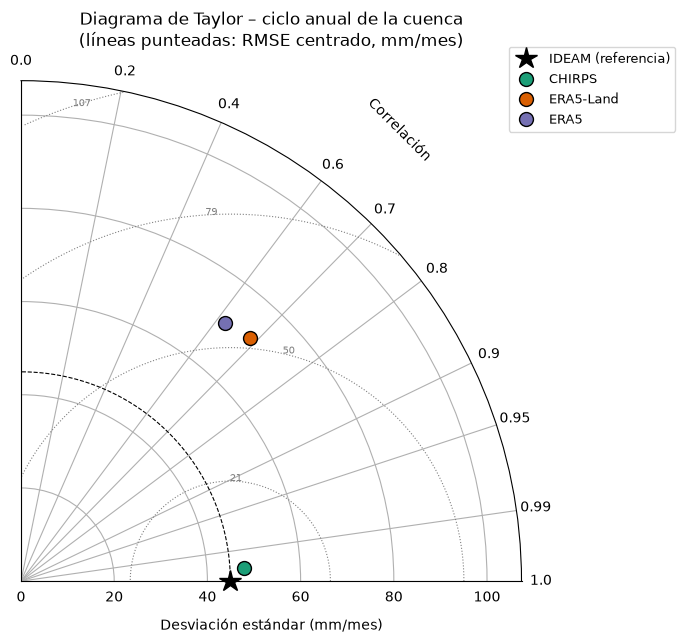

In [10]:
def diagrama_taylor(obs, sims, archivo):
    so = obs.std()
    fig = plt.figure(figsize=(7, 6.5))
    ax = fig.add_subplot(111, projection="polar")
    ax.set_thetamin(0); ax.set_thetamax(90)
    rmax = 1.5 * max([so] + [s.std() for s in sims.values()])
    ax.set_rlim(0, rmax)
    rt = np.array([0, .2, .4, .6, .7, .8, .9, .95, .99, 1])
    ax.set_thetagrids(np.degrees(np.arccos(rt)), [str(v) for v in rt])
    t = np.linspace(0, np.pi, 300)
    for c in np.linspace(rmax / 5, rmax, 4):                       # arcos de RMSE centrado
        x, y = so + c * np.cos(t), c * np.sin(t)
        rr, tt = np.hypot(x, y), np.arctan2(y, x)
        ok = (tt <= np.pi / 2) & (rr <= rmax)
        ax.plot(tt[ok], rr[ok], ls=":", color="gray", lw=0.8)
        if ok.any():
            j = np.where(ok)[0][len(np.where(ok)[0]) // 2]
            ax.text(tt[j], rr[j], f"{c:.0f}", fontsize=7, color="gray")
    ax.plot(np.linspace(0, np.pi / 2, 100), np.full(100, so), "k--", lw=0.8)
    ax.plot(0, so, "k*", ms=16, label="IDEAM (referencia)", clip_on=False)
    for n, s in sims.items():
        ax.plot(np.arccos(np.corrcoef(obs, s)[0, 1]), s.std(), "o", ms=10, color=COLOR[n], mec="k",
                label=NOMBRE[n], clip_on=False)
    ax.set_xlabel("Desviación estándar (mm/mes)", labelpad=22)
    ax.text(np.radians(48), rmax * 1.13, "Correlación", ha="center", rotation=-45)
    ax.legend(loc="upper right", bbox_to_anchor=(1.32, 1.08), fontsize=9)
    ax.set_title("Diagrama de Taylor – ciclo anual de la cuenca\n(líneas punteadas: RMSE centrado, mm/mes)", pad=25)
    fig.savefig(archivo, dpi=200, bbox_inches="tight")
    plt.show()


diagrama_taylor(obs, {p: ciclos[NOMBRE[p]].to_numpy() for p in PRODUCTOS if p != "IDEAM"}, "fig_taylor_ciclo_anual.png")

### 4.3 Distribución espacial de la precipitación
Hay dos comparaciones posibles, cada una con un defecto:
1. **Contra el mapa del IDEAM, celda por celda.** Ese mapa es una interpolación y no es la "verdad".
2. **Contra las estaciones, punto a píxel.** El valor del producto en la celda de cada estación dentro de la cuenca
   se compara con la P medida.
   - Para que la comparación sea justa con el IDEAM, a la interpolación se le asigna su error de **validación
     cruzada** del punto 3: el valor estimado sin usar esa estación.
   - La comparación tiene una limitación de escala: un píxel de 28 km (ERA5) no puede reproducir un valor puntual.

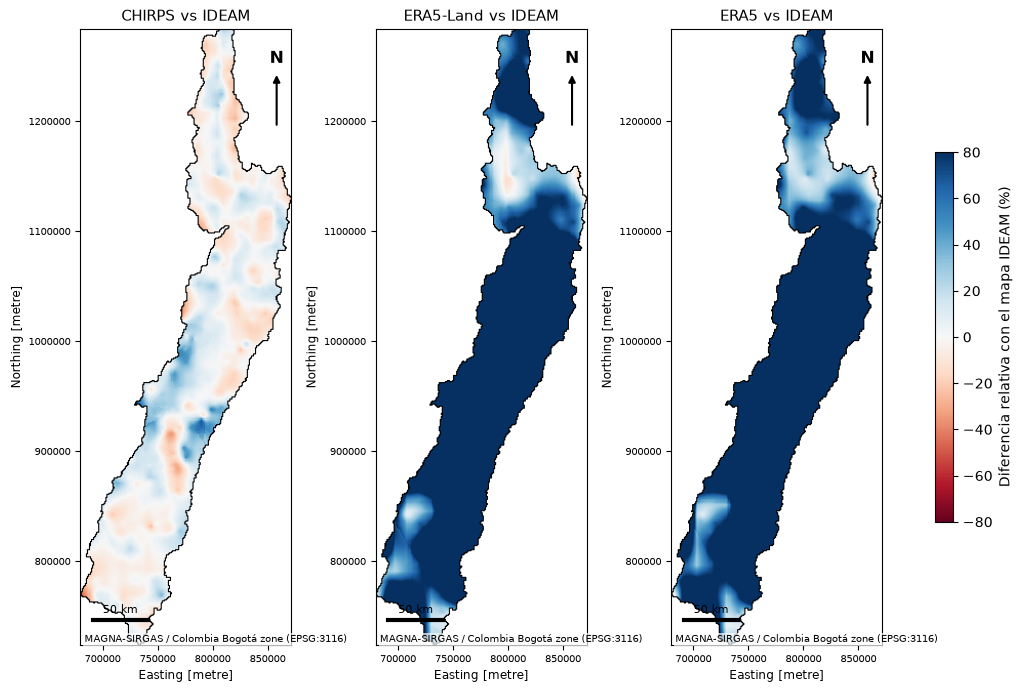

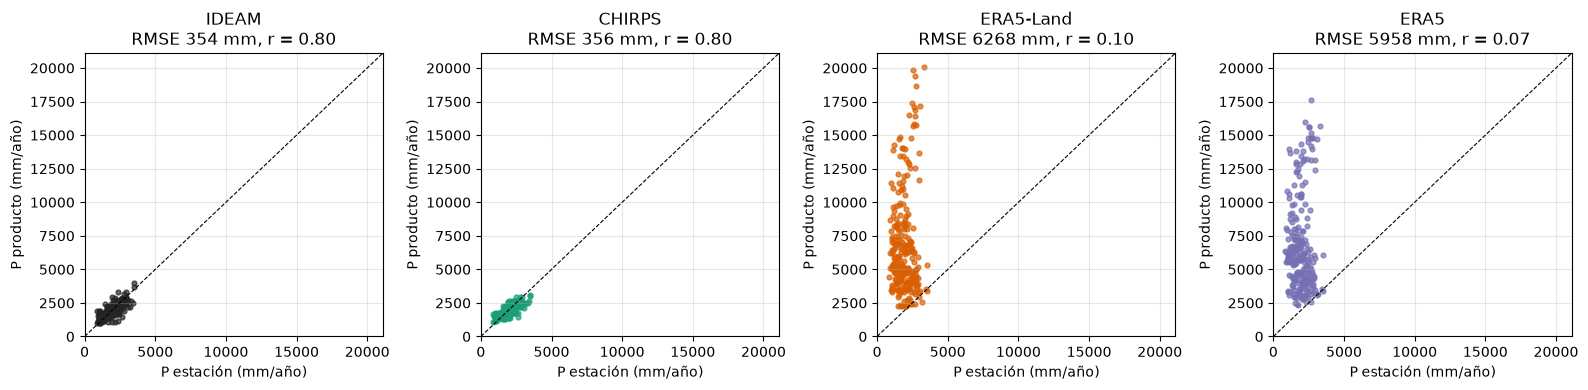

,r espacial (celdas),sesgo medio (mm/año),RMSE celdas (mm/año)
producto,,,
CHIRPS,0.90,16.01,236.84
ERA5-Land,-0.07,3989.83,5174.43
ERA5,-0.08,4006.19,5136.75


,n estaciones,sesgo (mm/año),RMSE (mm/año),r
producto,,,,
IDEAM (validación cruzada),250,19.85,354.27,0.80
CHIRPS,250,43.25,355.64,0.80
ERA5-Land,250,4958.36,6268.01,0.10
ERA5,250,4864.17,5957.53,0.07


In [11]:
fig, axs = plt.subplots(1, len(PRODUCTOS) - 1, figsize=(4.5 * (len(PRODUCTOS) - 1), 8))
filas = []
for ax, prod in zip(np.atleast_1d(axs), [p for p in PRODUCTOS if p != "IDEAM"]):
    rel = 100 * (anual[prod] / anual["IDEAM"] - 1)
    im = mapa(rel, info, f"{NOMBRE[prod]} vs IDEAM", "", cuenca, rio, cmap="RdBu", vmin=-80, vmax=80, ax=ax)
    a, b = anual[prod].compressed(), anual["IDEAM"].compressed()
    filas.append({"producto": NOMBRE[prod], "r espacial (celdas)": np.corrcoef(a, b)[0, 1],
                  "sesgo medio (mm/año)": (a - b).mean(), "RMSE celdas (mm/año)": np.sqrt(((a - b) ** 2).mean())})
fig.colorbar(im, ax=axs, shrink=0.6, label="Diferencia relativa con el mapa IDEAM (%)")
fig.savefig("fig_diferencias_espaciales.png", dpi=200, bbox_inches="tight")
plt.show()
esp_mapa = pd.DataFrame(filas).set_index("producto")

est = pd.read_csv(ESTACIONES_P)
est = est[est.ubicacion == "dentro"].copy()
for prod in PRODUCTOS:
    if prod == "IDEAM":
        est["IDEAM"] = est["P_estimada_LOO"] if "P_estimada_LOO" in est else np.nan
    else:
        est[prod] = [valor_en_punto(anual[prod], info, x, y) for x, y in zip(est.x, est.y)]
filas = []
fig, axs = plt.subplots(1, len(PRODUCTOS), figsize=(4 * len(PRODUCTOS), 4))
lim = [0, np.nanmax(est[["P_ANUAL"] + PRODUCTOS].to_numpy()) * 1.05]
for ax, prod in zip(np.atleast_1d(axs), PRODUCTOS):
    ok = est[prod].notna()
    o, s = est.loc[ok, "P_ANUAL"].to_numpy(), est.loc[ok, prod].to_numpy()
    if len(o) < 3:
        ax.axis("off"); continue
    filas.append({"producto": NOMBRE[prod] + (" (validación cruzada)" if prod == "IDEAM" else ""), "n estaciones": len(o),
                  "sesgo (mm/año)": (s - o).mean(), "RMSE (mm/año)": np.sqrt(((s - o) ** 2).mean()),
                  "r": np.corrcoef(o, s)[0, 1]})
    ax.scatter(o, s, s=12, alpha=0.7, color=COLOR[prod]); ax.plot(lim, lim, "k--", lw=0.8)
    ax.set(xlim=lim, ylim=lim, xlabel="P estación (mm/año)", ylabel="P producto (mm/año)",
           title=f"{NOMBRE[prod]}\nRMSE {filas[-1]['RMSE (mm/año)']:.0f} mm, r = {filas[-1]['r']:.2f}")
    ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("fig_punto_pixel.png", dpi=200)
plt.show()
esp_est = pd.DataFrame(filas).set_index("producto")
display(esp_mapa.round(2)); display(esp_est.round(2))

## 5. Síntesis: ¿qué producto representa mejor cada aspecto?
Para cada criterio se ordenan los tres productos (1 = mejor):
1. **Precipitación media de largo plazo:** el menor |diferencia %| con la P anual de la cuenca del IDEAM.
2. **Balance hídrico:** el menor error absoluto medio en Q, del punto 12.
3. **Ciclo anual:** el menor RMSE del ciclo de la cuenca. La correlación y el diagrama de Taylor complementan.
4. **Distribución espacial:** el menor RMSE frente a las estaciones (punto a píxel).

In [12]:
prods = [NOMBRE[p] for p in PRODUCTOS if p != "IDEAM"]
sint = pd.DataFrame(index=prods)
sint["1. |dif. P media| (%)"] = [abs(met.loc[p, "Bias (%)"]) for p in prods]
if os.path.exists(RESUMEN_BALANCE):
    rb = pd.read_csv(RESUMEN_BALANCE, index_col=0)
    sint["2. error abs. medio en Q (%)"] = [rb.loc[p, "error_abs_medio_pct"] if p in rb.index else np.nan for p in prods]
sint["3. RMSE ciclo (mm/mes)"] = [met.loc[p, "RMSE (mm/mes)"] for p in prods]
sint["3b. r ciclo"] = [met.loc[p, "r"] for p in prods]
sint["4. RMSE en estaciones (mm/año)"] = [esp_est.loc[p, "RMSE (mm/año)"] if p in esp_est.index else np.nan for p in prods]
rank = sint.drop(columns=["3b. r ciclo"]).rank(axis=0, method="min")
rank.columns = [c.split(" ")[0] + " puesto" for c in rank.columns]
tabla = pd.concat([sint.round(2), rank.astype("Int64")], axis=1)
tabla["puesto promedio"] = rank.mean(axis=1).round(2)
tabla = tabla.sort_values("puesto promedio")
tabla.to_csv("sintesis_productos.csv", encoding="utf-8-sig")
display(tabla)
print(f"Producto con mejor desempeño global en esta cuenca: {tabla.index[0]}")

,1. |dif. P media| (%),2. error abs. medio en Q (%),3. RMSE ciclo (mm/mes),3b. r ciclo,4. RMSE en estaciones (mm/año),1. puesto,2. puesto,3. puesto,4. puesto,puesto promedio
CHIRPS,0.80,NaN,4.30,1.00,355.64,1,<NA>,1,1,1.00
ERA5-Land,199.39,NaN,336.58,0.68,6268.01,2,<NA>,2,3,2.33
ERA5,200.21,NaN,338.42,0.62,5957.53,3,<NA>,3,2,2.67


Producto con mejor desempeño global en esta cuenca: CHIRPS


### Guía para la discusión final (ajústela a sus números)
- **Precipitación media:** compare la P anual de cada producto con la del IDEAM.
  - En los Andes es frecuente que **ERA5 y ERA5-Land sobrestimen** la lluvia sobre las cordilleras y que su baja
    resolución "aplane" los contrastes.
  - **CHIRPS**, que está corregido con estaciones (muchas del IDEAM), suele acercarse más en magnitud.
  - Que un producto se parezca al IDEAM **no garantiza** que sea correcto: el IDEAM también subestima en las zonas
    altas sin estaciones.
- **Balance hídrico:** el mejor juez es el caudal observado, porque integra toda la cuenca. Un producto puede
  diferir del IDEAM y aun así cerrar mejor el balance; eso indicaría que el IDEAM subestima la P de cuenca.
- **Ciclo anual:**
  - Revise si cada producto reproduce el régimen bimodal, los meses de los máximos (abril–mayo y octubre–noviembre)
    y la profundidad del "veranillo" de mitad de año.
  - Una r alta con un sesgo grande indica buena estacionalidad pero mala magnitud.
- **Distribución espacial:** la resolución importa. Con 0,05°, CHIRPS puede representar el valle seco y las
  vertientes húmedas; ERA5, con 0,25°, cubre la cuenca con pocos píxeles.
- **Conclusión:** indique qué producto recomendaría para estudios hidrológicos en la cuenca y para qué propósito
  (balance de largo plazo, estacionalidad o análisis espacial). Si ninguno es el mejor en todo, dígalo.